# Dual-Process Trait-Based Essay Scoring

We implement the system from **Xiao et al., "Human-AI Collaborative Essay Scoring: A Dual-Process Framework with LLMs"** (LAK 2025, [arXiv 2401.06431](https://doi.org/10.48550/arXiv.2401.06431)).

**One model, two ways of answering:**

- **Slow module:** LLaMA-3-8B, fine-tuned to read the essay and *write* its scores (slow, but it reasons in text).
- **Fast module:** a small classifier on top of the same fine-tuned model's *embeddings* (very fast, and it gives a confidence for every score).
- **Rule:** use the fast score. If its confidence is below **0.2**, ask the slow module instead.

In the paper (ASAP Set 1, overall score), the fast module reached QWK **0.758** and the full system **0.761**.

**Data:** ASAP essay set 1 (1,783 essays) with trait scores from ASAP++. We predict the overall score plus 5 traits.

**Run on:** Google Colab or Kaggle with a **T4 GPU**. Training takes about 1 hour.

## Step 1: Install the libraries

[Unsloth](https://github.com/unslothai/unsloth) is the library the paper used. It makes fine-tuning an 8B model fit on a free 16 GB GPU.

In [5]:
!pip install -q unsloth

## Step 2: Settings

All the numbers the paper used are here, so you can change them in one place.

We work inside a Google Drive folder, `MyDrive/essay-scoring`, so the data and the trained model are not lost when Colab disconnects.

**Before running:** in Google Drive, put these two files in `MyDrive/essay-scoring/data/`:

1. `training_set_rel3.tsv`, from the zip on the [ASAP Kaggle page](https://www.kaggle.com/c/asap-aes)
2. The ASAP++ trait file for prompt 1, from the [ASAP++ page](https://lwsam.github.io/ASAP++/lrec2018.html)

On Kaggle instead of Colab: delete the Drive lines and set the two file paths to `/kaggle/input/...`.

In [6]:
import os
from google.colab import drive
drive.mount("/content/drive")
os.makedirs("/content/drive/MyDrive/essay-scoring/data", exist_ok=True)
os.chdir("/content/drive/MyDrive/essay-scoring")

ASAP_FILE   = "/content/training_set_rel3.tsv"
ASAPPP_FILE = "/content/Prompt-1.csv" # ASAP++ traits for set 1 (.xlsx or .csv)
ESSAY_SET   = 1

MODEL_NAME  = "unsloth/llama-3-8b-bnb-4bit"  # same 4-bit LLaMA-3-8B as the paper
MAX_SEQ_LEN = 1280
THRESHOLD   = 0.2    # paper: below this confidence, use the slow module
SEED        = 42     # paper: seed 42 for the 80/20 split

os.makedirs("models", exist_ok=True)
for f in [ASAP_FILE, ASAPPP_FILE]:
    print(f, "found" if os.path.exists(f) else "MISSING: upload it to MyDrive/essay-scoring/data/")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/training_set_rel3.tsv MISSING: upload it to MyDrive/essay-scoring/data/
/content/Prompt-1.csv MISSING: upload it to MyDrive/essay-scoring/data/


## Step 3: Load and join the data

ASAP gives the essay and its **overall** score. ASAP++ gives the **trait** scores for the same essays. We join them on `essay_id`.

If the join gives 0 rows, print `traits.columns` and fix the name of the ID column.

In [9]:
import json, re
import numpy as np
import pandas as pd

asap = pd.read_csv(ASAP_FILE, sep="\t", encoding="latin-1")
asap = asap[asap.essay_set == ESSAY_SET][["essay_id", "essay", "domain1_score"]]
asap = asap.rename(columns={"domain1_score": "overall"})

read = pd.read_excel if ASAPPP_FILE.endswith(".xlsx") else pd.read_csv
traits = read(ASAPPP_FILE)
traits.columns = [c.strip().lower().replace(" ", "_") for c in traits.columns]
traits = traits.rename(columns={"essayid": "essay_id"})

df = asap.merge(traits, on="essay_id")
TRAITS = ["overall"] + [c for c in traits.columns if c != "essay_id"]
RANGES = {t: (int(df[t].min()), int(df[t].max())) for t in TRAITS}

print(len(df), "essays")
print(RANGES)
df.head()

1783 essays
{'overall': (2, 12), 'content': (1, 6), 'organization': (1, 6), 'word_choice': (1, 6), 'sentence_fluency': (1, 6), 'conventions': (1, 6)}


,essay_id,essay,overall,content,organization,word_choice,sentence_fluency,conventions
0,1,"Dear local newspaper, I think effects computer...",8,4,3,3,3,3
1,2,"Dear @CAPS1 @CAPS2, I believe that using compu...",9,4,4,4,3,4
2,3,"Dear, @CAPS1 @CAPS2 @CAPS3 More and more peopl...",7,3,3,3,4,4
3,4,"Dear Local Newspaper, @CAPS1 I have found that...",10,5,4,5,4,4
4,5,"Dear @LOCATION1, I know having computers has a...",8,4,3,4,4,4


## Step 4: Split into train and test (80 / 20)

Same split as the paper: 80% to train, 20% to test, seed 42. We also keep 10% of the training essays aside as a small **dev set** to check the fast classifier.

In [10]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.2, random_state=SEED)
fit_df, dev_df = train_test_split(train_df, test_size=0.1, random_state=SEED)
print("train:", len(train_df), " test:", len(test_df))

train: 1426  test: 357


## Step 5: Build the prompt

We use the same prompt layout as the paper (its Table 9): instruction, rubric, essay prompt, essay, then the answer.

The answer is a small JSON object with one score per trait, for example `{"overall": 9, "content": 4, ...}`.

The essay prompt and rubric below are short summaries. For better results, paste the official text from the `Essay Set #1` description file that comes with the ASAP download.

In [11]:
ESSAY_PROMPT = ("Write a letter to your local newspaper giving your opinion on the effects "
                "computers have on people. Persuade the readers to agree with you.")

RUBRIC = f"""overall ({RANGES['overall'][0]}-{RANGES['overall'][1]}): the sum of two teachers' holistic scores.
Trait scores (1-6, higher is better):
- content: clear position, strong and relevant reasons and examples
- organization: logical order, clear introduction and conclusion, good transitions
- word_choice: precise, varied and persuasive words
- sentence_fluency: varied, smooth and well-built sentences
- conventions: correct spelling, grammar, punctuation and capitalization"""

TEMPLATE = """Below is an instruction that describes a task, paired with an input that provides further context. Write a response that appropriately completes the request.

### Instruction:
You are an experienced English teacher grading student essays with a rubric. Score the essay on each trait. Answer only with JSON in this format: {fmt}

### Input:
Scoring rubric:
{rubric}

Essay prompt:
{prompt}

Student's essay:
{essay}

### Response:
"""

def build_prompt(essay):
    essay = " ".join(essay.split()[:700])          # cut very long essays
    fmt = json.dumps({t: 0 for t in TRAITS})
    return TEMPLATE.format(fmt=fmt, rubric=RUBRIC, prompt=ESSAY_PROMPT, essay=essay)

def build_answer(row):
    return json.dumps({t: int(row[t]) for t in TRAITS})

print(build_prompt(df.essay.iloc[0])[:900])
print(build_answer(df.iloc[0]))

Below is an instruction that describes a task, paired with an input that provides further context. Write a response that appropriately completes the request.

### Instruction:
You are an experienced English teacher grading student essays with a rubric. Score the essay on each trait. Answer only with JSON in this format: {"overall": 0, "content": 0, "organization": 0, "word_choice": 0, "sentence_fluency": 0, "conventions": 0}

### Input:
Scoring rubric:
overall (2-12): the sum of two teachers' holistic scores.
Trait scores (1-6, higher is better):
- content: clear position, strong and relevant reasons and examples
- organization: logical order, clear introduction and conclusion, good transitions
- word_choice: precise, varied and persuasive words
- sentence_fluency: varied, smooth and well-built sentences
- conventions: correct spelling, grammar, punctuation and capitalization

Essay prom
{"overall": 8, "content": 4, "organization": 3, "word_choice": 3, "sentence_fluency": 3, "conventio

## Step 6: Load LLaMA-3-8B and add LoRA

We load the model in 4-bit so it fits on the GPU, then add **LoRA**: small extra layers that we train while the big model stays frozen.

Paper settings: rank 16, alpha 16.

In [12]:
from unsloth import FastLanguageModel, is_bfloat16_supported
import torch

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_NAME, max_seq_length=MAX_SEQ_LEN, load_in_4bit=True)

model = FastLanguageModel.get_peft_model(
    model, r=16, lora_alpha=16, lora_dropout=0,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    use_gradient_checkpointing="unsloth", random_state=3407)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1124 12:59:28.978000 462 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1124 12:59:29.024000 462 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.10: Fast Llama patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Unsloth: Will load unsloth/llama-3-8b-bnb-4bit as a legacy tokenizer.
Unsloth 2026.11.10 patched 32 layers with 32 QKV layers, 32 O layers and 32 MLP layers.


Unsloth: compiling each transformer block as one region (LlamaDecoderLayer).


## Step 7: Fine-tune (this trains the slow module)

Each training example is the prompt followed by the correct JSON answer. The model learns to write the right scores.

Paper settings: learning rate 2e-4, 50 warm-up steps, linear decay, weight decay 0.01, 8-bit AdamW, 2 epochs, seed 3407.

In [13]:
from datasets import Dataset
from trl import SFTTrainer, SFTConfig

texts = [build_prompt(r.essay) + build_answer(r) + tokenizer.eos_token for _, r in train_df.iterrows()]
train_ds = Dataset.from_dict({"text": texts})

trainer = SFTTrainer(
    model=model, tokenizer=tokenizer, train_dataset=train_ds,
    args=SFTConfig(
        dataset_text_field="text", max_seq_length=MAX_SEQ_LEN,
        per_device_train_batch_size=2, gradient_accumulation_steps=4,
        num_train_epochs=2, learning_rate=2e-4, warmup_steps=50,
        lr_scheduler_type="linear", weight_decay=0.01, optim="adamw_8bit",
        fp16=not is_bfloat16_supported(), bf16=is_bfloat16_supported(),
        logging_steps=10, seed=3407, output_dir="outputs",save_steps=50, save_total_limit=2,report_to="none"))

import glob
has_checkpoint = len(glob.glob("outputs/checkpoint-*")) > 0
trainer.train(resume_from_checkpoint=has_checkpoint)

model.save_pretrained("models/llama3_aes_lora")      # save the LoRA weights
tokenizer.save_pretrained("models/llama3_aes_lora")

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/1426 [00:00<?, ? examples/s]

Unsloth: Packing train dataset (num_proc=2):   0%|          | 0/1426 [00:00<?, ? examples/s]

Unsloth: Packing is on by default - documents are packed into full rows with no cross-document attention. Set packing = False in SFTConfig (or UNSLOTH_DEFAULT_PACKING=0) to turn it off.


	save_steps: 50 (from args) != 500 (from trainer_state.json)
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 1,043 | Num Epochs = 2 | Total steps = 262
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 41,943,040 of 8,072,204,288 (0.52% trained)


Step,Training Loss


Unsloth: Restored added_tokens_decoder metadata in models/llama3_aes_lora/tokenizer_config.json.


('models/llama3_aes_lora/tokenizer_config.json',
 'models/llama3_aes_lora/tokenizer.json')

In [14]:
model.save_pretrained("models/llama3_aes_lora")
tokenizer.save_pretrained("models/llama3_aes_lora")

('models/llama3_aes_lora/tokenizer_config.json',
 'models/llama3_aes_lora/tokenizer.json')

## Step 8: Slow module: the model writes the scores

We give the model the prompt and let it write the JSON answer. Then we read the numbers out of the text. If the answer cannot be read, we return `None`.

In [15]:
FastLanguageModel.for_inference(model)

def parse_scores(text):
    match = re.search(r"\{.*?\}", text, re.S)
    try:
        scores = json.loads(match.group())
        return {t: int(np.clip(round(float(scores[t])), *RANGES[t])) for t in TRAITS}
    except Exception:
        return None

@torch.no_grad()
def slow_score(essay):
    inputs = tokenizer(build_prompt(essay), return_tensors="pt").to("cuda")
    out = model.generate(**inputs, max_new_tokens=100, do_sample=False)
    return parse_scores(tokenizer.decode(out[0][inputs.input_ids.shape[1]:], skip_special_tokens=True))

print(slow_score(test_df.essay.iloc[0]))
print(test_df[TRAITS].iloc[0].to_dict())

Both `max_new_tokens` (=100) and `max_length`(=8192) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


{'overall': 6, 'content': 3, 'organization': 3, 'word_choice': 3, 'sentence_fluency': 3, 'conventions': 3}
{'overall': 6, 'content': 2, 'organization': 2, 'word_choice': 2, 'sentence_fluency': 2, 'conventions': 2}


## Step 9: Fast module, part 1: get an embedding for each essay

Instead of letting the model write, we run it **once** over the prompt and take its last hidden layer. We average it over all tokens to get one vector (4,096 numbers) per essay.

This uses what the model learned during fine-tuning. Takes about 10 minutes.

In [16]:
from tqdm.auto import tqdm

@torch.no_grad()
def embed(essay):
    inputs = tokenizer(build_prompt(essay), return_tensors="pt").to("cuda")
    out = model(**inputs, output_hidden_states=True)
    if out.hidden_states is not None:
        hidden = out.hidden_states[-1]
    else:  # some Unsloth versions skip hidden_states; run the inner model instead
        hidden = model.get_base_model().model(**inputs).last_hidden_state
    return hidden[0].mean(dim=0).float().cpu().numpy()

X_fit  = np.stack([embed(e) for e in tqdm(fit_df.essay)])
X_dev  = np.stack([embed(e) for e in tqdm(dev_df.essay)])
X_test = np.stack([embed(e) for e in tqdm(test_df.essay)])
np.savez("models/embeddings.npz", fit=X_fit, dev=X_dev, test=X_test)

  0%|          | 0/1283 [00:00<?, ?it/s]

  0%|          | 0/143 [00:00<?, ?it/s]

  0%|          | 0/357 [00:00<?, ?it/s]

## Step 10: Fast module, part 2: train a classifier per trait

The paper adds "a simple fully connected layer" on the embeddings. A logistic regression is exactly that: one layer + softmax. We train one per trait.

Its output is a **probability for every possible score**, which gives us the confidence.

`C` controls how strongly the classifier is held back. If dev QWK is much lower than you expect, try `C = 0.01` or `C = 1`.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import cohen_kappa_score

def qwk(y_true, y_pred):
    return cohen_kappa_score(y_true, y_pred, weights="quadratic")

scaler = StandardScaler().fit(X_fit)
heads = {}
for t in TRAITS:
    heads[t] = LogisticRegression(C=0.1, max_iter=2000).fit(scaler.transform(X_fit), fit_df[t])
    print(f"{t:18s} dev QWK = {qwk(dev_df[t], heads[t].predict(scaler.transform(X_dev))):.3f}")

overall            dev QWK = 0.778
content            dev QWK = 0.679
organization       dev QWK = 0.618
word_choice        dev QWK = 0.637
sentence_fluency   dev QWK = 0.668
conventions        dev QWK = 0.686


## Step 11: Confidence

The paper turns the score probabilities into a confidence but does not give the exact formula. We use the highest probability, rescaled so that:

- **0** = no better than a random guess
- **1** = completely sure

This makes traits with different numbers of possible scores comparable. A trait below `THRESHOLD` (0.2) is "low confidence".

In [18]:
def fast_score(X):
    """Returns (scores, confidence) tables: one row per essay, one column per trait."""
    Xs = scaler.transform(X)
    scores, conf = {}, {}
    for t, head in heads.items():
        probs = head.predict_proba(Xs)
        k = probs.shape[1]
        scores[t] = head.classes_[probs.argmax(1)]
        conf[t] = (probs.max(1) - 1 / k) / (1 - 1 / k)
    return pd.DataFrame(scores), pd.DataFrame(conf)

fast_pred, fast_conf = fast_score(X_test)
fast_conf.describe().round(2)

,overall,content,organization,word_choice,sentence_fluency,conventions
count,357.00,357.00,357.00,357.00,357.00,357.00
mean,0.76,0.79,0.81,0.81,0.81,0.80
std,0.20,0.20,0.19,0.19,0.19,0.19
min,0.26,0.18,0.28,0.31,0.30,0.25
25%,0.59,0.65,0.67,0.66,0.68,0.64
50%,0.80,0.85,0.88,0.90,0.89,0.87
75%,0.95,0.96,0.98,0.97,0.97,0.97
max,1.00,1.00,1.00,1.00,1.00,1.00


## Step 12: Dual process: fast first, slow when unsure

For every test essay we keep the fast scores. If **any** trait is below the threshold, we call the slow module once and replace only the low-confidence traits.

In [19]:
final_pred = fast_pred.copy()
low = fast_conf < THRESHOLD
need_slow = low.any(axis=1)
print(f"Slow module needed for {need_slow.sum()} of {len(test_df)} essays")

for i in tqdm(np.where(need_slow)[0]):
    slow = slow_score(test_df.essay.iloc[i])
    if slow is None:
        continue                          # keep the fast scores if the text can't be read
    for t in TRAITS:
        if low.loc[i, t]:
            final_pred.loc[i, t] = slow[t]

Slow module needed for 1 of 357 essays


  0%|          | 0/1 [00:00<?, ?it/s]

Both `max_new_tokens` (=100) and `max_length`(=8192) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


## Step 13: Results

QWK per trait for the fast module alone and for the full dual-process system. Compare the **overall** row with the paper (Set 1: fast 0.758, full system 0.761).

In [20]:
results = pd.DataFrame({
    "fast module": [qwk(test_df[t], fast_pred[t]) for t in TRAITS],
    "dual process": [qwk(test_df[t], final_pred[t]) for t in TRAITS]}, index=TRAITS)
results.loc["average"] = results.mean()
results.round(3).to_csv("results_qwk.csv")
results.round(3)

,fast module,dual process
overall,0.786,0.786
content,0.730,0.728
organization,0.708,0.708
word_choice,0.647,0.647
sentence_fluency,0.669,0.669
conventions,0.667,0.667
average,0.701,0.701


## Step 14: Does confidence mean anything?

The paper's Figure 3 shows that the fast module is more accurate when it is more confident. We check the same thing for the overall score. Groups with very few essays give noisy QWK, so read the counts too.

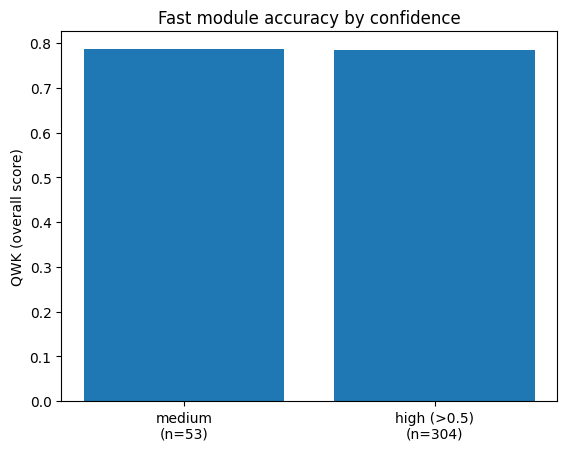

In [21]:
import matplotlib.pyplot as plt

bins = pd.cut(fast_conf["overall"], [-0.01, 0.2, 0.5, 1.0], labels=["low (<0.2)", "medium", "high (>0.5)"])
groups = [(name, g.index) for name, g in fast_conf.groupby(bins, observed=True) if len(g) > 1]
names = [f"{n}\n(n={len(idx)})" for n, idx in groups]
values = [qwk(test_df["overall"].iloc[idx], fast_pred["overall"].iloc[idx]) for _, idx in groups]

plt.bar(names, values)
plt.ylabel("QWK (overall score)")
plt.title("Fast module accuracy by confidence")
plt.savefig("confidence_plot.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 15: Score a new essay (this is what the website will call)

Save the classifiers (and the prompt texts, so the website uses exactly the same prompt), then use `score_essay` for any new set-1 essay. It returns each trait's score, its confidence, and which module gave it.

In [22]:
import joblib
joblib.dump({"scaler": scaler, "heads": heads, "ranges": RANGES,
             "essay_prompt": ESSAY_PROMPT, "rubric": RUBRIC, "template": TEMPLATE},
            "models/fast_heads.joblib")

def score_essay(essay):
    scores, conf = fast_score(embed(essay)[None, :])
    result = {t: {"score": int(scores[t][0]), "confidence": round(float(conf[t][0]), 2), "module": "fast"}
              for t in TRAITS}
    low = [t for t in TRAITS if conf[t][0] < THRESHOLD]
    if low:
        slow = slow_score(essay)
        if slow:
            for t in low:
                result[t].update(score=slow[t], module="slow")
    return result

score_essay(test_df.essay.iloc[0])

{'overall': {'score': 6, 'confidence': 0.82, 'module': 'fast'},
 'content': {'score': 2, 'confidence': 0.69, 'module': 'fast'},
 'organization': {'score': 2, 'confidence': 0.91, 'module': 'fast'},
 'word_choice': {'score': 2, 'confidence': 0.87, 'module': 'fast'},
 'sentence_fluency': {'score': 2, 'confidence': 0.97, 'module': 'fast'},
 'conventions': {'score': 2, 'confidence': 0.98, 'module': 'fast'}}